In [1]:
import torch
import numpy as np
from sklearn.datasets import load_wine
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from torch import Tensor
from torch.nn import Sequential, Linear, ReLU, CrossEntropyLoss, Module
from torch.utils.data import DataLoader, Dataset
from torch.optim import Adam
import matplotlib.pyplot as plt

In [2]:
class MyDataset(Dataset):
    def __init__(self, datas: np.ndarray, labels: np.ndarray) -> None:
        self._x = torch.from_numpy(datas).float()
        self._y = torch.from_numpy(labels).long()

    def __len__(self) -> int:
        return len(self._x)

    def __getitem__(self, idx: int) -> tuple[Tensor, Tensor]:
        int(idx)
        return self._x[idx], self._y[idx]

In [3]:
class CustomModel(Module):
    def __init__(self, input_size: int, output_size) -> None:
        super().__init__()
        self.net = Sequential(
            Linear(input_size, 32),
            ReLU(),
            Linear(32,16),
            ReLU(),
            Linear(16, output_size)
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.net(x)

In [4]:
def train_model_class(features, targets, kf, batch, epochs, criterion, exp=False):
    acc_scores = []
    f1_scores = []
    folds_loss = []
    folds_acc = []
    for i, (train_index, test_index) in enumerate(kf.split(features, targets)):
        print(f"Treinando modelo ----- Fold {i + 1}")
        train_data = MyDataset(features[train_index], targets[train_index])
        train_loader = DataLoader(train_data, batch_size=batch)
        model = CustomModel(13, 3)
        optmizer = Adam(model.parameters(), lr=0.001)
        epoch_loss = []
        epoch_acc = []
        for i_epochs in range(epochs):    
            model.train()
            batches_loss = []
            batches_acc = []
            for x, y in train_loader:
                optmizer.zero_grad()
                output = model(x)
                loss = criterion(output, y)
                loss.backward()
                optmizer.step()
                batches_loss.append(loss.item())
                batches_acc.append(accuracy_score(y, torch.argmax(output, dim=1).cpu().numpy()))

            epoch_loss.append(np.mean(batches_loss))
            epoch_acc.append(np.mean(batches_acc))

        folds_loss.append(epoch_loss)
        folds_acc.append(epoch_acc)
        model.eval()
        with torch.no_grad():
            x_test_tensor = Tensor(features[test_index]).float()
            y_true = targets[test_index]
            output = model(x_test_tensor)
            result = torch.argmax(output, dim=1).cpu().numpy()
            acc_s = accuracy_score(y_true, result)
            f1_s = f1_score(y_true, result, average="macro")
            cm = confusion_matrix(y_true, result)
            acc_scores.append(acc_s)
            f1_scores.append(f1_s)
            print(f"Acc: {acc_s}")
            print(f"F1-Score: {f1_s}")
            print(f"CM: {cm}")

        if exp:
            break

    print(f"\nResultado modelo ----- Acc: {np.mean(acc_scores)}, F1-Score: {np.mean(f1_scores)}")

    return folds_loss, folds_acc

In [5]:
def plot_loss(folds_loss, folds_acc):
    folds_acc = folds_acc * 100
    for idx, fold_l in enumerate(folds_loss):
        fig, ax1 = plt.subplots(figsize=(7, 3))
        x = np.linspace(0, len(fold_l), len(fold_l))
        ax1.plot(x, fold_l, color="red", label="Erro")
        ax1.set_xlabel("Épocas")
        ax1.set_ylabel("Erro")
        ax1.set_ylim(0, 0.2)
        ax2 = ax1.twinx()
        ax2.plot(x, folds_acc[idx], color="blue", label="Acc")
        ax2.set_ylabel("Acurácia")
        ax2.set_ylim(0.8, 1.1)
        ax2.grid()
        fig.legend()
        fig.show()

In [6]:
dataset = load_wine()
features = dataset.data
targets = dataset.target

In [7]:
criterion = CrossEntropyLoss()
max_epochs = 2000
batch = 8
kf = StratifiedKFold(n_splits=5, shuffle=True)

In [8]:
folds_loss, folds_acc = train_model_class(features, targets, kf, batch, max_epochs, criterion, True)

Treinando modelo ----- Fold 1
Acc: 0.9722222222222222
F1-Score: 0.9717813051146384
CM: [[12  0  0]
 [ 0 13  1]
 [ 0  0 10]]

Resultado modelo ----- Acc: 0.9722222222222222, F1-Score: 0.9717813051146384


C:\Users\gavia\AppData\Local\Temp\ipykernel_9996\3649337085.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


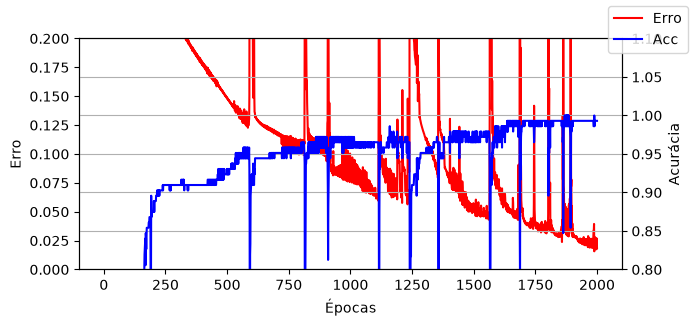

In [9]:
plot_loss(folds_loss, folds_acc)